# Pycavi illumination correction via Chebyshev polynomials

This notebook checks the calibration of swarped image calibrated in the previous step.

  - Reads the swarped image and some necessary keywords.
  - Read the catalogue used to calibrate the image.
  - Produce several plots that can be used to determine the quality of the photometry.
  - Saves the resulting plot into a file

The next step is to determine the illumination correction, an effect that can
imprint systematic variations above 0.2 mags accross the field for wide field
imagers such as OmegaCam and WFI. Pycavi offers two ways to determine the illumination correction: 

  1. **chebyshev polynomial fit**, fast and convenient because one saves a limited number of coefficients. The user should test with different degree polynomials and check the residual standard deviation of each, together with the presence of possible large scale variations. It is suggested to use the lowest degree polynomials that gives the minimum  standard deviation. Experimentation shows that the standard deviation decreases as one increases the degree, until a minimum, and then increases due to polynomial oscilations at larger degrees. Chebyshev gives reasonable solutions with very low degrees of freedom.

At this point the illumination correction is shown as a colour image with contours overlaid.
The image is saved to a file with root name equal to the image root name in the Calibration directory.

  - After the illumination correction determination the photometry is corrected and the
residuals are ploted for both the corrected magnitudes and the raw magnitudes. Two plots
are generated for QC purposes: a residuals versus x-coordinates for the uncorrected points
in red, and the corrected points in black; and a histogram of the residuals for both
sets of points. The mean, median and 1-sigma variation is reported in these plots.
The plots are saved with the root-name of the image plus a string giving the type
of correction and the string _res_01.png at the end.

  - Another set of plots is presented with the residuals as a function of radius, azimuthal
angle measured from the center of the FoV, and versus x and y. These plots have similar names
as the previous set, but with end string _res_02.png.



In [1]:
import os
import sys
import glob
import copy
import logging

import numpy as np
from numpy.polynomial import chebyshev
import pandas as pd

#import matplotlib.pyplot as plt
#import matplotlib.gridspec as gridspec
#from matplotlib import cm
#from mpl_toolkits.axes_grid1 import make_axes_locatable

from astropy.stats import sigma_clipped_stats, sigma_clip
from astropy.visualization import simple_norm
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from astropy.wcs import WCS

from scipy.interpolate import griddata, Rbf
from scipy.stats import norm

from photutils.aperture import SkyCircularAperture, SkyCircularAnnulus, aperture_photometry


#   from pycavi_astromatic import SExtractor
sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production

from pycavi import pycavi_tools
from pycavi.pycavi_zpcal import extract_calibration, plot_zpcal, get_files_dict, save_illumination_data, read_illumination_data
from pycavi.pycavi_zpcal import plot_residuals, plot_illumination_correction, plot_corrected_residuals, plot_spatial_residuals
from pycavi.pycavi_chebyshev import fit_chebyshev, chebyshev_2d_eval, chebyshev_polynomials, evaluate_2dpoly, append_hashline
from pycavi.pycavi_kriging import kriging_interpolation, determine_kriging_errors


This will be executed when the package is imported.


In [11]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
illum_files = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        directory = os.path.dirname(zpcal_dict[observation_tags[i]][j])
        file_name_noext = os.path.splitext(os.path.basename(zpcal_dict[observation_tags[i]][j]))[0]
        illum_file = os.path.join(directory, file_name_noext)+ '.illum.csv'
        if os.path.isfile(illum_file):
            illum_files.append(illum_file)

for i in range(len(illum_files)):
    logging.info("index: {} -- illum: {}".format(i, illum_files[i]))



2024-10-28 16:43:35,887:INFO:index: 0 -- illum: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_NB_659.coadd.illum.csv
2024-10-28 16:43:35,888:INFO:index: 1 -- illum: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_r_SDSS.coadd.illum.csv


2024-10-28 16:43:43,900:INFO:image_name: CN_Ori_r_SDSS.coadd
2024-10-28 16:43:43,905:WARNING:Input data contains invalid values (NaNs or infs), which were automatically clipped.
2024-10-28 16:43:43,907:INFO:Filtering: number of data points 6189 ---> 3406 (19031 19878)


Index(['x_all', 'y_all', 'mag_std', 'mag_frame', 'z_all', 'z_all_err'], dtype='object')


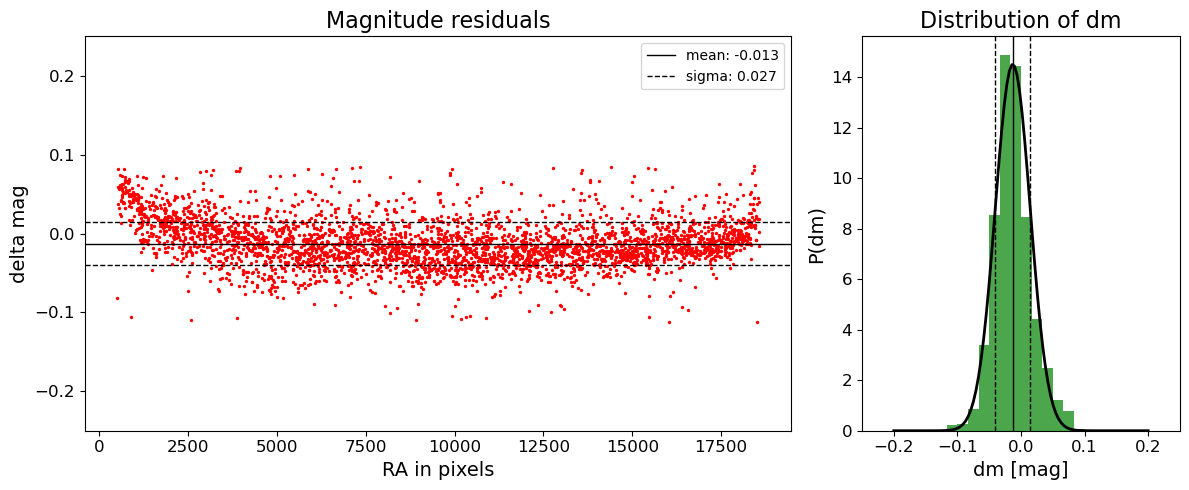

2024-10-28 16:43:44,160:INFO:-------Done-------


In [12]:
# Here we loop over the images selected
# See list above to select a data partition to calibrate
# For example, if the list is:
#
# index: 0 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/CP_Pup/Swarp_dir/CP_Pup_r_SDSS.coadd.fits
# index: 1 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_g_SDSS.coadd.fits
# index: 2 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_r_SDSS.coadd.fits
# index: 3 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_NB_659.coadd.fits
# index: 4 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_g_SDSS.coadd.fits
# index: 5 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_r_SDSS.coadd.fits
# index: 6 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA98/Swarp_dir/SA98_NB_659.coadd.fits
#
# then to calibrate M67_NB_659.coadd.fits set
#
# idx_selected = [3]
#

idx_selected = [1]    # Keep empty to check all files
for i in range(len(illum_files)):
    
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue

    # For checking we read it again and continue with plotting
    headers, data_df = read_illumination_data(illum_files[i])
    #display(data_df)
    print(data_df.columns)

    x_all = data_df['x_all']
    y_all = data_df['y_all']
    z_all = data_df['z_all']
    z_all_err = data_df['z_all_err']
    mag_std = data_df['mag_std']

    dimx = int(headers['dimx'])
    dimy = int(headers['dimy'])
    origfile = headers['origfile']
    image_dir = headers['image_dir']
    image_name = headers['image_name']
    image_path = headers['image_path']
    band = headers['band']
    logging.info(f"image_name: {image_name}")
    
    brightest_mag = 12.0
    faintest_mag = 18.0
    dm_min = -0.25
    dm_max = 0.25

    z_all_clipped = sigma_clip(z_all, sigma=3.0, maxiters=5)
    mask = ~np.isnan(z_all) & ~z_all_clipped.mask & np.isfinite(z_all) & \
        (brightest_mag < mag_std) & (mag_std < faintest_mag) & \
        (dm_min < z_all) & (z_all < dm_max)
    x_subset = x_all[mask]
    y_subset = y_all[mask]
    z_subset = z_all[mask]
    z_subset_err = z_all_err[mask]

    n_before_filter = len(x_all)
    n_after_filter = len(x_subset)
    logging.info("Filtering: number of data points {} ---> {} ({} {})".format(n_before_filter, n_after_filter, dimx, dimy))

    ############################ 03 PLOT RESIDUALS AND PDF FOR UNCORRECTED DATA ####################
    #
    plot_residuals(x_subset, z_subset, ylim=(-0.25, 0.25))


        

    
logging.info("-------Done-------")

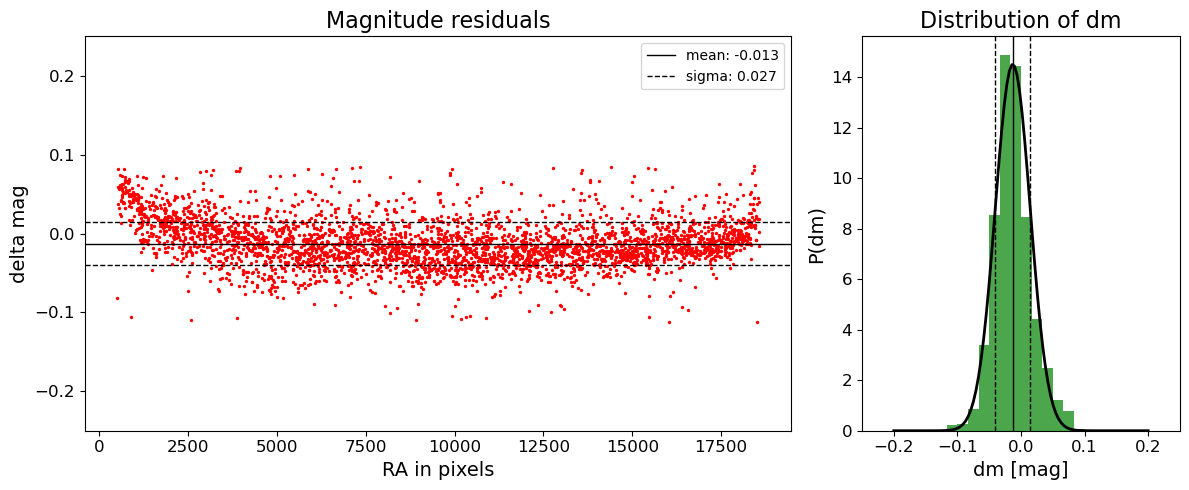

In [13]:
############################ 03 PLOT RESIDUALS AND PDF FOR UNCORRECTED DATA ####################
#
plot_residuals(x_subset, z_subset, ylim=(-0.25, 0.25))

In [14]:
#################################### 04 FIT RESIDUAL DATA ###############################
#

# Here I add new code
# Define the grid size
n_pts = 50j
print(dimx, dimy, n_pts)
grid_x, grid_y = np.mgrid[1:dimx:n_pts,1:dimy:n_pts]

############ FIT ##########
# we fit a 2D Chebyshev polynomial of degrees deg
#
# NB. The coefficients work on coordinates scaled to (-1, 1) in both axes
#
deg = (5, 5)
zz_corr, coeffs, residuals, rank, s = fit_chebyshev(x_subset, y_subset, z_subset, z_subset_err, dimx, dimy, deg)
inter_type = 'rbf'    # inter_type: 'cubic' or 'rbf' -- note that cubic uses 'linear' near the edges.

# Define some strings for plotting    
fit_image_title = f"{image_name}: cheb ({deg[0]},{deg[1]}) fit to residuals"
fit_plot = image_path+"_cheb_"+f"{deg[0]}_{deg[1]}_"+inter_type+"_fit_01.png"
coeff_file = image_path+"_cheb_"+f"{deg[0]}_{deg[1]}_"+inter_type+"_fit_01.chebyshev"
res_plot_str = image_path+"_cheb_"+f"{deg[0]}_{deg[1]}_"+inter_type+"_res"

############## USE POLYNOMIAL DIRECTLY ###########
# we get explicit expressions for the polynomials
# We do this to ensure that the expressions we provide, perhaps in headers,
# have been validated by this notebook.
#
# The function chebyshev_polynomial store the fitted polynomial in file coeff_file
#
coefficients, cheb_poly_x_strdic, cheb_poly_y_strdic = chebyshev_polynomials(deg, coeffs, coeff_file, origfile, dimx=dimx, dimy=dimy)
corrections = evaluate_2dpoly(x_subset, y_subset, dimx, dimy, deg, cheb_poly_x_strdic, cheb_poly_y_strdic, coefficients)
z_corr = z_subset - corrections

z_mean_u, z_median_u, z_std_u = sigma_clipped_stats(z_subset, sigma=3.0, maxiters=5)
logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean_u, 4), round(z_median_u, 4), round(z_std_u, 4)))

z_mean, z_median, z_std = sigma_clipped_stats(z_corr, sigma=3, maxiters=5)
logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean, 4), round(z_median, 4), round(z_std, 4)))

# We save information into the headers of the coeff file if using Chebysheb
append_hashline(coeff_file, f"# uncorrected median: {round(z_median_u,4)}, mean: {round(z_mean_u,4)}, sigma: {round(z_std_u,4)}")
append_hashline(coeff_file, f"# corrected median: {round(z_median,4)}, mean: {round(z_mean,4)}, sigma: {round(z_std,4)} factor: {round(z_std_u/z_std, 2)}")
append_hashline(coeff_file, f"# dm_min: {dm_min}")
append_hashline(coeff_file, f"# dm_max: {dm_max}")
append_hashline(coeff_file, f"# brightest_mag: {brightest_mag}")
append_hashline(coeff_file, f"# faintest_mag: {faintest_mag}")
append_hashline(coeff_file, f"# image_name: {image_name}")
    
# we display the results of the fit as an image
# NB: for Chebyshev we fit the whole data set as the
#     method does not have the issue of exact interpolation
#     at the input points, and have fewer degrees of freedom.
#

################### EVALUATE POLYNOMIAL ON REGULAR GRID #######################
#
# chebyshev_2d_eval(x_pix, y_pix, coeff, deg)
#
if 'cubic' in inter_type:
    grid_z_cubic = griddata((x_subset, y_subset),
                       evaluate_2dpoly(x_subset, y_subset, dimx, dimy, deg, cheb_poly_x_strdic, cheb_poly_y_strdic, coefficients)
                       #chebyshev_2d_eval(x_subset, y_subset, dimx, dimy, coeffs, deg), 
                      (grid_x, grid_y), method='cubic')
    grid_z_nearest = griddata((x_subset, y_subset), 
                       #chebyshev_2d_eval(x_subset, y_subset, dimx, dimy, coeffs, deg),
                       evaluate_2dpoly(x_subset, y_subset, dimx, dimy, deg, cheb_poly_x_strdic, cheb_poly_y_strdic, coefficients)
                      (grid_x, grid_y), method='nearest')
    grid_z = np.where(np.isnan(grid_z_cubic), grid_z_nearest, grid_z_cubic)
elif 'rbf' in inter_type:
    rbf = Rbf(x_subset, y_subset, chebyshev_2d_eval(x_subset, y_subset, dimx, dimy, coeffs, deg), function='cubic')
    grid_z = rbf(grid_x, grid_y)
        
grid_z = grid_z.T
    
print("grid_z.shape: {}".format(grid_z.shape))

# Due to the low number of degrees of freedom for Chebyshev check points are all points
x_check = x_subset
y_check = y_subset
z_check = z_subset
err_type = "err_simple"
determine_errors = True    # To inform downstream procedures that we have error estimates in the form of the *_check arrays


logging.info("######################### DONE ######################")


2024-10-28 16:43:54,450:INFO:coefficients.shape: (6, 6)
2024-10-28 16:43:54,451:INFO:01 Coefficient(0, 0): 0.00252489 * T_0(x) * T_0(y)
2024-10-28 16:43:54,452:INFO:02 Coefficient(0, 1): 0.00400453 * T_0(x) * T_1(y)
2024-10-28 16:43:54,454:INFO:03 Coefficient(0, 2): 0.00436463 * T_0(x) * T_2(y)
2024-10-28 16:43:54,457:INFO:04 Coefficient(0, 3): 0.00141953 * T_0(x) * T_3(y)
2024-10-28 16:43:54,457:INFO:05 Coefficient(0, 4): -0.00707785 * T_0(x) * T_4(y)
2024-10-28 16:43:54,460:INFO:06 Coefficient(1, 0): -0.01859306 * T_1(x) * T_0(y)
2024-10-28 16:43:54,461:INFO:07 Coefficient(1, 1): 0.00267118 * T_1(x) * T_1(y)
2024-10-28 16:43:54,462:INFO:08 Coefficient(1, 2): -0.00527157 * T_1(x) * T_2(y)
2024-10-28 16:43:54,462:INFO:09 Coefficient(1, 3): -0.00080586 * T_1(x) * T_3(y)
2024-10-28 16:43:54,464:INFO:10 Coefficient(1, 4): -0.00145696 * T_1(x) * T_4(y)
2024-10-28 16:43:54,465:INFO:11 Coefficient(2, 0): 0.02181726 * T_2(x) * T_0(y)
2024-10-28 16:43:54,466:INFO:12 Coefficient(2, 1): 0.003112

19031 19878 50j


2024-10-28 16:43:54,521:INFO:mean: -0.0129  --  median: -0.0149  --  stdev: 0.0275
2024-10-28 16:43:54,523:INFO:mean: -0.0015  --  median: -0.0026  --  stdev: 0.0177
2024-10-28 16:43:55,078:INFO:######################### DONE ######################


grid_z.shape: (50, 50)


2024-10-28 16:43:59,877:INFO:Saving fit plot to /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_r_SDSS.coadd_cheb_5_5_rbf_fit_01.png


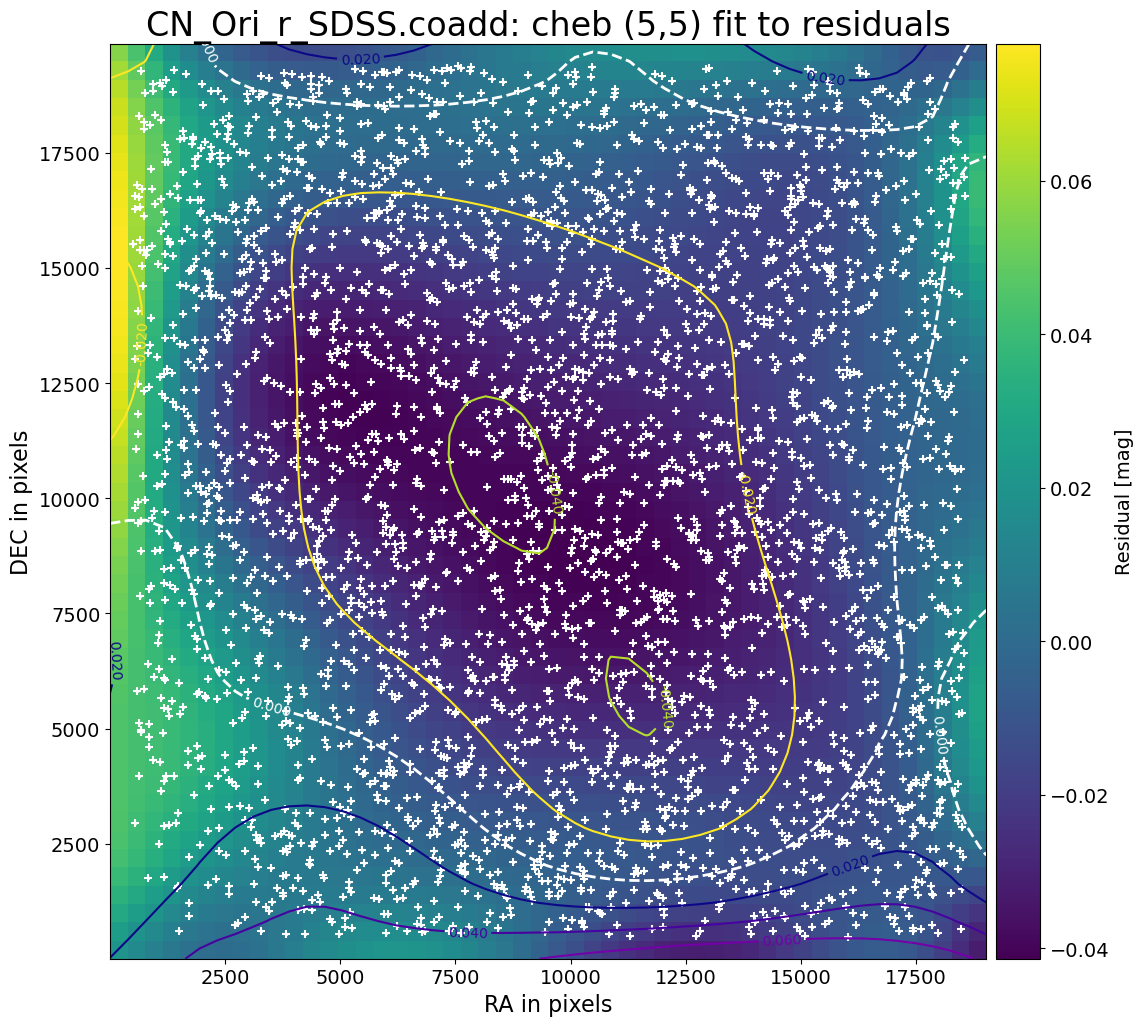

In [15]:
########################################## 05 PLOT APPROXIMATING SURFACE ###########################
#
plot_illumination_correction(x_subset, y_subset, x_check, y_check, grid_x, grid_y, grid_z, dimx, dimy, fit_plot, fit_image_title)

2024-10-28 16:44:06,524:INFO:mean: -0.0129  --  median: -0.0149  --  stdev: 0.0275
2024-10-28 16:44:06,527:INFO:mean: -0.0015  --  median: -0.0026  --  stdev: 0.0177
2024-10-28 16:44:06,529:INFO:mean: -0.0129  --  median: -0.0149  --  stdev: 0.0275
2024-10-28 16:44:06,730:INFO:Saving residual plots to None


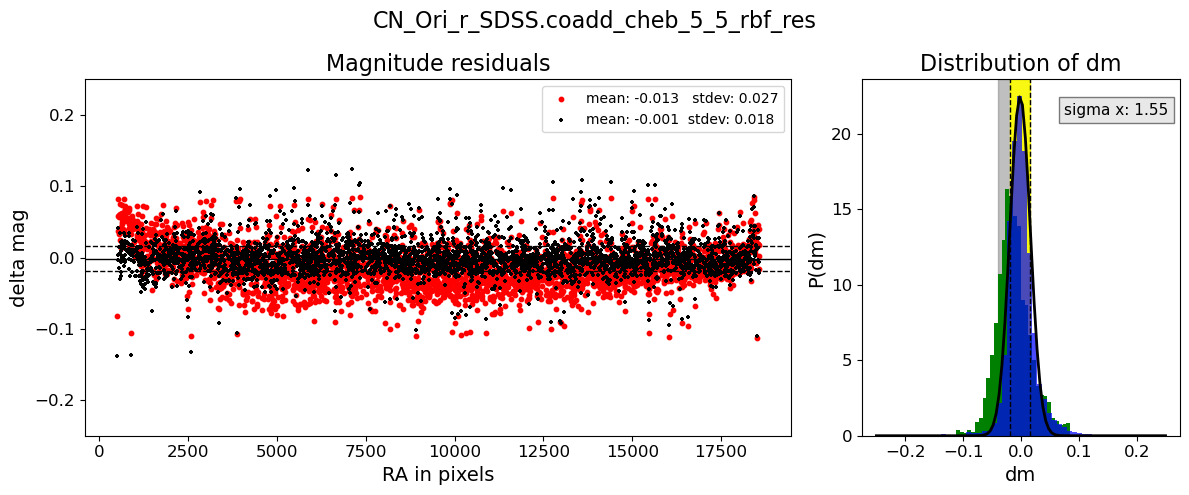

In [16]:
######################### PLOT RESIDUALS AND RMS ESTIMATE USING INDEPENDENT DATA POINTS ##################
#
#image_path = zpcal.image_path[:-5]
#image_name = image_name.split("/")[-1]

# In cases where edge oscilations are large  we might need to clip
# the max and minimum values.
min_corr = -0.20
max_corr = 0.25
#z_corr = np.clip(z_corr, min_corr, max_corr)

plot_corrected_residuals(x_subset, z_subset, z_corr, x_check, res_plot_str, determine_errors, err_type, ylim=(-0.25, 0.25))

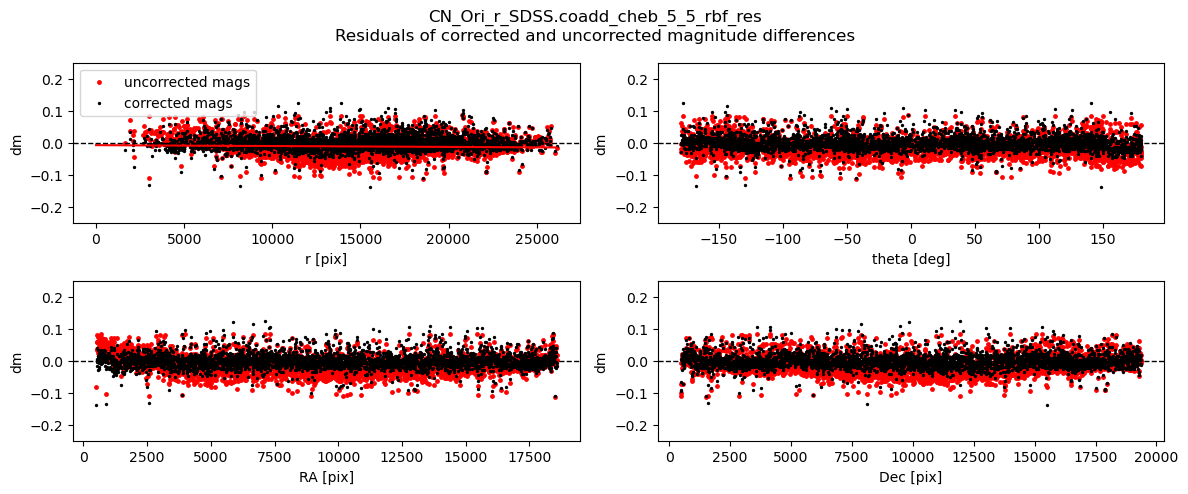

In [17]:
############################ EXTENSIVE SPATIAL PLOTS OF RESIDUALS ###########################
#    
plot_spatial_residuals(x_subset, y_subset, z_subset, z_corr, x_check, y_check, dimx, dimy, res_plot_str, err_type, ylim=(-0.25, 0.25))

In [10]:
# We anlyze the bright saturated end to see if we can model it
# DOES NOT WORK. RESULT IS CLOSER TO STRAIGHT LINE UNTIL
# SAT MAG WHERE IT IS 0.0
#
from scipy.optimize import curve_fit
def sat_model(x, m, c, k, x0):
    return c + (m / k) * np.log(1 + np.exp(k * (x0 -  x)**2))

model_non_linearity = True
if model_non_linearity and "Chebyshev" in method:
    z_std = zpcal.mag_std
    z_frame = zpcal.mag_frame
    dm = z_std - z_frame

    x_pix = zpcal.x
    y_pix = zpcal.y

    z_corr = z_std - (z_frame + chebyshev_2d_eval(x_pix, y_pix, dimx, dimy, coeffs, deg))

    # Estimación inicial de los parámetros [m, c, k, x0]
    initial_guess = [0.2, 0.8, 1.0, 13]

    # Ajustar la función a los datos
    good_data = ~np.isnan(z_corr) & np.isfinite(z_corr) & ~np.isnan(z_std) & np.isfinite(z_std)
    params, covariance = curve_fit(sat_model, z_std[good_data], z_corr[good_data], p0=initial_guess)

    # Generar los datos ajustados
    x_data = np.linspace(8, 19, 100)
    y_fitted = sat_model(x_data, *params)

    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    ax.scatter(z_std[good_data], z_corr[good_data], label='Datos', color='blue', s=3)
    ax.plot(x_data, y_fitted, label='Función ajustada', color='red')
    ax.set_ylim(-0.2, 0.2)
    ax.axhline(0.0, color='k', linewidth=1, linestyle='--')

    plt.show()

NameError: name 'method' is not defined

### 